# 01 — Data Preparation & Exploration: Amazon Reviews 2023 (Books)

**Objective.** Load the Amazon Reviews 2023 — Books category, clean it, explore
it, and produce the time-based train/val/test split that every later notebook
(baselines, MF-BPR, two-tower, ranking) will consume.

**Why this dataset.** Books gives us a large catalog with rich metadata (title,
category, image, price) for the webapp's item cards and content-side features,
plus enough scale (29.5M raw ratings) that subsampling to a recent, contiguous
window is a real design decision rather than a formality.

**This notebook produces:**
- `data/processed/train.parquet`, `val.parquet`, `test.parquet` — interactions with a `label` column
- `data/processed/items_meta.parquet` — item metadata for the surviving catalog

**Link to notebook in Kaggle:**
https://www.kaggle.com/code/goodoldies/full-recsys-data-prep-explore/

## 1. Setup

In [19]:
from pathlib import Path

DATA_ROOT = Path("/kaggle/working/data")
PROCESSED_DIR = DATA_ROOT / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR = Path("/kaggle/input/datasets/goodoldies/amazon-books")


In [20]:
import gzip
import json

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

## 2. Helper functions

Everything the rest of this notebook calls is defined here — parse
the raw dataset, build the sample, and the cleaning/split logic.

In [21]:
REVIEW_COLUMNS = ["user_id", "parent_asin", "rating", "timestamp", "verified_purchase"]
META_COLUMNS = ["parent_asin", "title", "main_category", "categories", "average_rating", "price", "image_url", "author"]

# Chart style — dataviz-skill validated palette (categorical, fixed order; do not re-sort per chart)
CATEGORICAL = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=CATEGORICAL), "font.family": "sans-serif", "figure.dpi": 110,
})


def _iter_jsonl(path: Path):
    """Iterate a JSONL file that may or may not be gzip-compressed.

    Kaggle Datasets auto-extract uploaded archives — including decompressing
    `.gz` files, not just unzipping — so a file we wrote as `Books.jsonl.gz`
    can land on Kaggle as plain `Books.jsonl`. We detect by magic bytes
    (gzip always starts with 0x1f 0x8b) rather than trusting the extension,
    since the filename doesn't reliably tell us which one we got.
    """
    with open(path, "rb") as f:
        is_gzip = f.read(2) == b"\x1f\x8b"
    opener = gzip.open(path, "rt", encoding="utf-8") if is_gzip else open(path, "rt", encoding="utf-8")
    with opener as f:
        for line in f:
            line = line.strip()
            if line:
                yield json.loads(line)


def _resolve_raw_file(dir_path: Path, stem: str) -> Path:
    """Find `{stem}.jsonl.gz` or `{stem}.jsonl` in `dir_path`, whichever exists.

    Same Kaggle auto-decompress issue as `_iter_jsonl`: we don't know ahead
    of time which extension the attached dataset will actually have.
    """
    gz_path, plain_path = dir_path / f"{stem}.jsonl.gz", dir_path / f"{stem}.jsonl"
    if gz_path.exists():
        return gz_path
    if plain_path.exists():
        return plain_path
    raise FileNotFoundError(f"Expected {gz_path} or {plain_path} — check Settings > Add Input.")

def parse_reviews_to_parquet(raw_gz_path: Path, out_path: Path, batch_rows: int = 1_000_000) -> Path:
    """Stream the raw review JSONL and write only the columns we need to Parquet.

    We drop review text/images here: they're not used by any model in this
    project, and keeping them would blow up memory/disk for no benefit.
    """
    if out_path.exists():
        print(f"Already parsed: {out_path}")
        return out_path
    out_path.parent.mkdir(parents=True, exist_ok=True)
    writer = None
    buf = {c: [] for c in REVIEW_COLUMNS}
    n_rows = 0
    try:
        for row in tqdm(_iter_jsonl(raw_gz_path), desc="parsing reviews"):
            buf["user_id"].append(row.get("user_id"))
            buf["parent_asin"].append(row.get("parent_asin") or row.get("asin"))
            buf["rating"].append(row.get("rating"))
            buf["timestamp"].append(row.get("timestamp"))
            buf["verified_purchase"].append(row.get("verified_purchase"))
            n_rows += 1
            if n_rows % batch_rows == 0:
                table = pa.table(buf)
                if writer is None:
                    writer = pq.ParquetWriter(out_path, table.schema)
                writer.write_table(table)
                buf = {c: [] for c in REVIEW_COLUMNS}
        if buf["user_id"]:
            table = pa.table(buf)
            if writer is None:
                writer = pq.ParquetWriter(out_path, table.schema)
            writer.write_table(table)
    finally:
        if writer is not None:
            writer.close()
    print(f"Wrote {n_rows:,} interactions -> {out_path}")
    return out_path


def _extract_image_url(images):
    """Pull a display-quality image URL out of whatever key shape this row's image dicts use.

    The metadata image schema isn't consistently documented across dataset
    versions, so instead of betting on one guessed key name, we try every
    plausible key and take the first hit.
    """
    if not images or not isinstance(images, list) or not isinstance(images[0], dict):
        return None
    entry = images[0]
    for key in ("hi_res", "large", "large_image_url", "thumb", "medium_image_url", "small_image_url", "variant"):
        val = entry.get(key)
        if val:
            return val
    return None


def _safe_float(value):
    """Coerce a possibly-messy raw price field ('$8.23', '', None, 8.23) to float or None."""
    if value is None:
        return None
    if isinstance(value, (int, float)):
        return float(value)
    try:
        return float(str(value).replace("$", "").replace(",", "").strip())
    except (ValueError, TypeError):
        return None


def _extract_author_name(author):
    """Pull the author's display name out of the nested `author` object.

    Not every item has a well-formed `author` field (missing entirely, or
    occasionally a list instead of a dict in some dataset snapshots), so this
    is defensive the same way `_extract_image_url` is.
    """
    if isinstance(author, dict):
        return author.get("name")
    if isinstance(author, list) and author and isinstance(author[0], dict):
        return author[0].get("name")
    return None


# Explicit output schema for items_raw.parquet. Without this, pyarrow infers
# each batch's schema independently from whatever Python values happen to be
# in it — if one 200k-row batch has every `average_rating`/`categories` value
# null/empty, that batch infers a null-ish type that then clashes with the
# `ParquetWriter` schema locked in by an earlier (or later) batch and crashes
# the run. Pinning the schema up front, which we need anyway now that
# `categories` is a list column instead of a scalar string, makes every
# batch's table conform to the same types regardless of what's null in it.
META_SCHEMA = pa.schema([
    ("parent_asin", pa.string()),
    ("title", pa.string()),
    ("main_category", pa.string()),
    ("categories", pa.list_(pa.string())),
    ("author", pa.string()),
    ("average_rating", pa.float64()),
    ("price", pa.float64()),
    ("image_url", pa.string()),
])


def parse_metadata_to_parquet(raw_gz_path: Path, out_path: Path, batch_rows: int = 200_000) -> Path:
    """Stream the raw item metadata JSONL and write title/category/author/image/price fields."""
    if out_path.exists():
        print(f"Already parsed: {out_path}")
        return out_path
    out_path.parent.mkdir(parents=True, exist_ok=True)
    writer = None
    buf = {c: [] for c in META_COLUMNS}
    n_rows = 0
    try:
        for row in tqdm(_iter_jsonl(raw_gz_path), desc="parsing metadata"):
            image_url = _extract_image_url(row.get("images"))
            # Keep the full categories path instead of collapsing it to a
            # single genre string. categories[0] is always "Books" (the root
            # category, same as main_category) since this file only contains
            # Books items in the first place; categories[1:] is the actual
            # genre path, e.g. ["Books", "Literature & Fiction", "United
            # States"]. Keeping the full list (rather than just categories[1])
            # lets downstream ranking features use more than the single
            # top-level genre, e.g. a category-overlap affinity feature.
            categories = row.get("categories") or []

            buf["parent_asin"].append(row.get("parent_asin") or row.get("asin"))
            buf["title"].append(row.get("title"))
            buf["main_category"].append(row.get("main_category"))
            buf["categories"].append(categories)            
            buf["average_rating"].append(row.get("average_rating"))
            buf["price"].append(_safe_float(row.get("price")))
            buf["image_url"].append(image_url)
            buf["author"].append(_extract_author_name(row.get("author")))
            
            n_rows += 1
            if n_rows % batch_rows == 0:
                table = pa.table(buf, schema=META_SCHEMA)
                if writer is None:
                    writer = pq.ParquetWriter(out_path, table.schema)
                writer.write_table(table)
                buf = {c: [] for c in META_COLUMNS}
        if buf["parent_asin"]:
            table = pa.table(buf, schema=META_SCHEMA)
            if writer is None:
                writer = pq.ParquetWriter(out_path, table.schema)
            writer.write_table(table)
    finally:
        if writer is not None:
            writer.close()
    print(f"Wrote {n_rows:,} items -> {out_path}")
    return out_path


def subsample_most_recent(df: pd.DataFrame, n: int, ts_col: str = "timestamp") -> pd.DataFrame:
    """Keep the `n` most recent interactions by timestamp — satisfies both the
    subsampling requirement and gives a contiguous window for the time split."""
    if len(df) <= n:
        return df
    return df.sort_values(ts_col, ascending=False).head(n).reset_index(drop=True)


def k_core_filter(df, min_user_interactions=5, min_item_interactions=5, user_col="user_id", item_col="parent_asin", max_iters=5):
    """Iteratively drop users/items below the activity floor until stable."""
    for _ in range(max_iters):
        before = len(df)
        item_counts = df[item_col].value_counts()
        df = df[df[item_col].isin(item_counts[item_counts >= min_item_interactions].index)]
        user_counts = df[user_col].value_counts()
        df = df[df[user_col].isin(user_counts[user_counts >= min_user_interactions].index)]
        if len(df) == before:
            break
    return df.reset_index(drop=True)


def time_based_split(df, val_frac=0.05, test_frac=0.05, ts_col="timestamp", user_col="user_id", item_col="parent_asin"):
    """Global timestamp-cutoff split, restricted to users/items already seen in train (warm-start eval)."""
    df = df.sort_values(ts_col)
    n = len(df)
    test_start = int(n * (1 - test_frac))
    val_start = int(n * (1 - test_frac - val_frac))

    train = df.iloc[:val_start]
    val = df.iloc[val_start:test_start]
    test = df.iloc[test_start:]

    train_users = set(train[user_col])
    train_items = set(train[item_col])
    val = val[val[user_col].isin(train_users) & val[item_col].isin(train_items)]
    test = test[test[user_col].isin(train_users) & test[item_col].isin(train_items)]

    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)



## 3. Get raw data

In [22]:
review_gz = _resolve_raw_file(RAW_DIR,  "Books.jsonl/Books")
meta_gz = _resolve_raw_file(RAW_DIR, "meta_Books.jsonl/meta_Books")

## 4. Parse to compact Parquet

The raw review file includes full review text, which we don't need for any
model in this project (MF-BPR and two-tower train on `user_id, item_id, rating,
timestamp`; content features come from metadata, not review text). We stream
the gzip line-by-line and project down to 5 columns immediately, writing in
1M-row batches so memory stays bounded regardless of the 29.5M-row file size.

In [23]:
interactions_raw_path = parse_reviews_to_parquet(review_gz, PROCESSED_DIR / "interactions_raw.parquet")
items_raw_path = parse_metadata_to_parquet(meta_gz, PROCESSED_DIR / "items_raw.parquet")

parsing reviews: 0it [00:00, ?it/s]

Wrote 29,475,453 interactions -> /kaggle/working/data/processed/interactions_raw.parquet


parsing metadata: 0it [00:00, ?it/s]

Wrote 4,448,181 items -> /kaggle/working/data/processed/items_raw.parquet


In [24]:
interactions = pd.read_parquet(interactions_raw_path)
interactions["timestamp"] = pd.to_datetime(interactions["timestamp"], unit="ms")
print(f"{len(interactions):,} raw interactions | "
      f"{interactions['user_id'].nunique():,} users | "
      f"{interactions['parent_asin'].nunique():,} items")
interactions.head()

29,475,453 raw interactions | 10,297,355 users | 4,446,065 items


,user_id,parent_asin,rating,timestamp,verified_purchase
0,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,B09BGPFTDB,1.0,2022-01-17 06:06:38.485,True
1,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,0593235657,5.0,2021-12-27 18:26:44.904,True
2,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1782490671,5.0,2021-12-24 22:04:55.102,True
3,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,0593138228,5.0,2021-12-24 16:55:06.602,False
4,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,0823098079,5.0,2021-11-19 08:57:33.230,True


## 5. Subsample to the most recent 5M interactions

**Design decision.** The full dataset (29.5M interactions) exceeds the 5M cap,
so per the project spec we subsample — but instead of a random sample, we keep
the most recent 5M interactions by timestamp. This does double duty: it satisfies
the subsampling requirement *and* gives us a single contiguous, chronologically
ordered window to carve the time-based split from in Section 9. A random sample
would scatter timestamps across the full 2000-2023 history and make "train on the
past, test on the future" meaningless.


In [25]:
SUBSAMPLE_N = 5_000_000
interactions = subsample_most_recent(interactions, SUBSAMPLE_N)
print(f"{len(interactions):,} interactions after subsampling "
      f"({interactions['timestamp'].min().date()} -> {interactions['timestamp'].max().date()})")

5,000,000 interactions after subsampling (2020-07-25 -> 2023-09-14)


## 6. Exploratory analysis

### 6.1 Sparsity

In [26]:
n_users = interactions["user_id"].nunique()
n_items = interactions["parent_asin"].nunique()
n_inter = len(interactions)
density = n_inter / (n_users * n_items)
print(f"users={n_users:,}  items={n_items:,}  interactions={n_inter:,}")
print(f"density = {density:.2e}  (i.e. {density*100:.5f}% of the user-item matrix is filled)")

users=2,687,830  items=1,297,409  interactions=5,000,000
density = 1.43e-06  (i.e. 0.00014% of the user-item matrix is filled)


**Interpretation.** Expect density on the order of 1e-5 to 1e-6 — typical for
Amazon review data, far sparser than MovieLens. This is the core argument for
k-core filtering below: at this density, most users/items have too few
interactions for any retrieval model to learn a meaningful embedding, and
evaluation metrics would be dominated by users we can't possibly serve well.

### 6.2 Rating distribution
Ratings are kept for EDA and as an item/user feature later, but no longer
drive the relevance label (see Section 8) — every interaction counts as relevant.

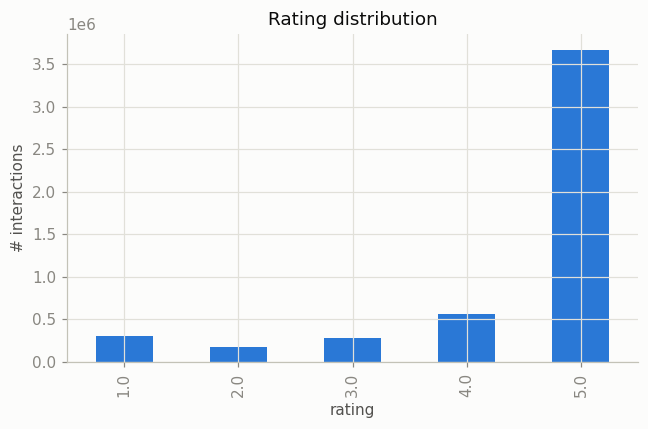

rating
1.0     6.1
2.0     3.6
3.0     5.7
4.0    11.3
5.0    73.3
Name: proportion, dtype: float64


In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
interactions["rating"].value_counts().sort_index().plot(kind="bar", ax=ax, color=CATEGORICAL[0])
ax.set_xlabel("rating")
ax.set_ylabel("# interactions")
ax.set_title("Rating distribution")
plt.tight_layout()
plt.show()

print(interactions["rating"].value_counts(normalize=True).sort_index().mul(100).round(1))

**Interpretation.** Amazon ratings skew heavily positive (typically ~65-75% are 4-5 stars). 

### 6.3 Long tail — interactions per user and per item

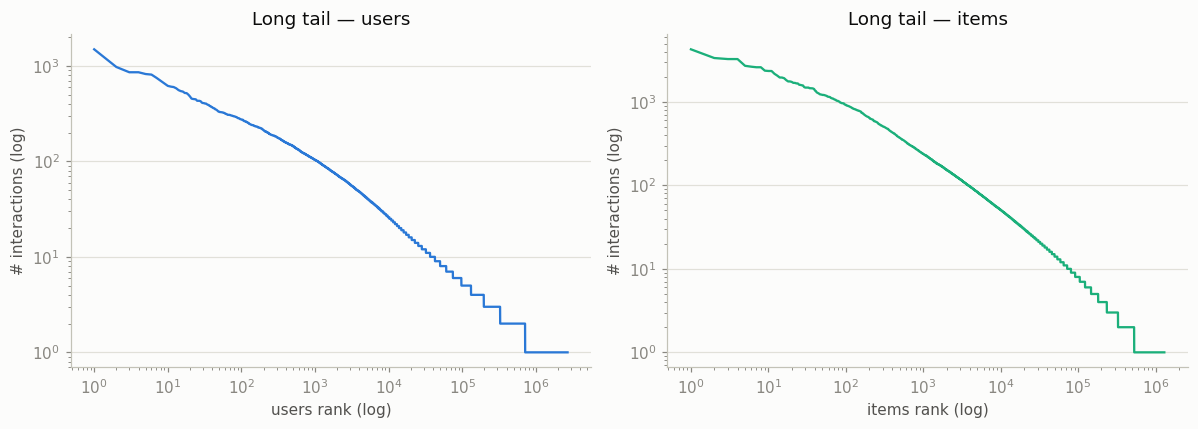

median interactions/user = 1, 90th pct = 3, max = 1490
median interactions/item = 1, 90th pct = 6, max = 4260


In [28]:
user_counts = interactions["user_id"].value_counts().values
item_counts = interactions["parent_asin"].value_counts().values

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, counts, label, color in zip(
    axes, [user_counts, item_counts], ["users", "items"], CATEGORICAL[:2]
):
    ax.plot(np.arange(1, len(counts) + 1), np.sort(counts)[::-1], color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"{label} rank (log)")
    ax.set_ylabel("# interactions (log)")
    ax.set_title(f"Long tail — {label}")
plt.tight_layout()
plt.show()

print(f"median interactions/user = {np.median(user_counts):.0f}, "
      f"90th pct = {np.percentile(user_counts, 90):.0f}, max = {user_counts.max()}")
print(f"median interactions/item = {np.median(item_counts):.0f}, "
      f"90th pct = {np.percentile(item_counts, 90):.0f}, max = {item_counts.max()}")

**Interpretation.** Both distributions should show the classic power-law long
tail — a small head of very active users/popular books and a massive tail with
only 1-2 interactions. The tail is exactly why we apply a k-core floor next: a
user with a single training interaction gives a retrieval model nothing to learn
from, and an item with one interaction can never be meaningfully evaluated by
Recall@K. We keep the floor low (Section 7) specifically so the tail isn't erased
entirely — the cold-start analysis in ANALYSIS.md needs low-activity users to exist.

### 6.4 Temporal patterns

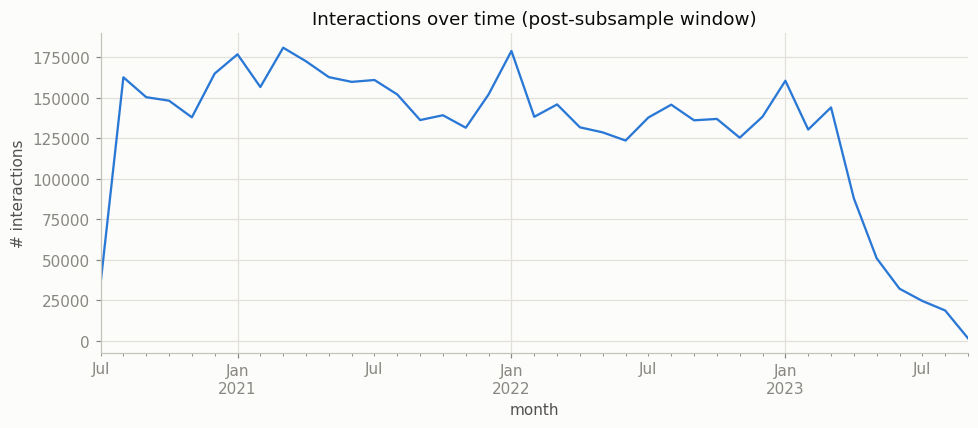

In [29]:
monthly = interactions.set_index("timestamp").resample("MS").size()
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, color=CATEGORICAL[0])
ax.set_xlabel("month")
ax.set_ylabel("# interactions")
ax.set_title("Interactions over time (post-subsample window)")
plt.tight_layout()
plt.show()

**Interpretation.** Note any strong upward/downward trend or seasonal spikes
(e.g. holiday shopping). A rising trend toward the end of the window is expected
since Amazon review volume grew over time; this also means the test period
(most recent slice) is denser than train's earliest months, which is worth
flagging when we discuss the split below.

## 7. k-core filtering

**Design decision.** We iteratively drop users and items below a low activity
floor (min 5 interactions each) until the set is stable. This is *not* meant to
fix sparsity broadly — it's the minimum needed so that (a) every remaining item
can plausibly appear in a Recall@K denominator, and (b) every remaining user has
enough history to make a train/test split meaningful for them. Threshold=5 is
deliberately low; a higher floor (e.g. 20) would make the problem easier but
would defeat the cold-start analysis required in ANALYSIS.md.

In [30]:
MIN_INTERACTIONS = 5
before = len(interactions)
interactions = k_core_filter(interactions, MIN_INTERACTIONS, MIN_INTERACTIONS)
after = len(interactions)
print(f"{before:,} -> {after:,} interactions ({(before - after) / before:.1%} dropped)")
print(f"{interactions['user_id'].nunique():,} users | {interactions['parent_asin'].nunique():,} items remain")

5,000,000 -> 658,838 interactions (86.8% dropped)
49,235 users | 43,014 items remain


## 8. Define positive interaction

In [31]:
# Relevance = "the user interacted with this book at all" (rating irrelevant) —
# every interaction is a positive/relevant signal, not just >=4-star ones.
interactions["label"] = 1
print(f"{len(interactions):,} interactions, all labeled relevant (label=1) under the any-interaction definition")

658,838 interactions, all labeled relevant (label=1) under the any-interaction definition


## 9. Load item metadata

In [32]:
items_meta = pd.read_parquet(items_raw_path)
items_meta = items_meta[items_meta["parent_asin"].isin(interactions["parent_asin"])].drop_duplicates("parent_asin")
print(f"{len(items_meta):,} items with metadata retained")
items_meta.head()

43,014 items with metadata retained


,parent_asin,title,main_category,categories,author,average_rating,price,image_url
19,B003P2WETK,Inspector Imanishi Investigates (Soho Crime),Buy a Kindle,"[Books, Mystery, Thriller & Suspense, Thriller...",Seicho Matsumoto,4.0,9.99,https://m.media-amazon.com/images/I/51UHERs91b...
157,125023655X,Cleo Porter and the Body Electric,Books,"[Books, Children's Books, Science Fiction & Fa...",Jake Burt,4.5,9.59,https://m.media-amazon.com/images/I/51hWlklilj...
207,1401293220,Whistle: A New Gotham City Hero,Books,"[Books, Teen & Young Adult, Literature & Fiction]",E. Lockhart,4.4,10.69,https://m.media-amazon.com/images/I/41yLEyvMOZ...
209,054545901X,Prisoner B-3087,Books,"[Books, Teen & Young Adult, Literature & Fiction]",Alan Gratz,4.7,15.49,https://m.media-amazon.com/images/I/510rCQy29O...
440,015603462X,The Republic of Pirates: Being the True and Su...,Books,"[Books, Biographies & Memoirs, True Crime]",Colin Woodard,4.5,9.89,https://m.media-amazon.com/images/I/51csKvULn0...


## 10. Time-based train / validation / test split
#
**Design decision (mandatory per project spec — random split scores 0 here).**
We use a global timestamp cutoff: the most recent 5% of interactions become
`test`, the 5% before that become `val`, and everything earlier is `train`. This
simulates real deployment — the model only ever sees the past at serving time.
#
We additionally restrict `val`/`test` to users *and* items already present in
`train`. A retrieval model has no embedding for an item it never saw in
training, so including unseen items in the eval set would just inject
unrecoverable misses into every metric. This is a "warm-start" evaluation
setting — the true cold-item/cold-user case is a real limitation, and we
discuss it explicitly in ANALYSIS.md rather than let it silently distort the
main metrics.

In [33]:
train, val, test = time_based_split(interactions, val_frac=0.05, test_frac=0.05)

summary = pd.DataFrame({
    "interactions": [len(train), len(val), len(test)],
    "users": [train["user_id"].nunique(), val["user_id"].nunique(), test["user_id"].nunique()],
    "items": [train["parent_asin"].nunique(), val["parent_asin"].nunique(), test["parent_asin"].nunique()],
    "date_min": [train["timestamp"].min(), val["timestamp"].min(), test["timestamp"].min()],
    "date_max": [train["timestamp"].max(), val["timestamp"].max(), test["timestamp"].max()],
}, index=["train", "val", "test"])
summary

,interactions,users,items,date_min,date_max
train,592954,48199,40366,2020-07-25 04:22:45.475,2023-01-18 13:11:56.526
val,18656,10179,8446,2023-01-18 13:19:26.380,2023-03-05 18:15:17.696
test,10234,6096,6114,2023-03-05 18:20:32.063,2023-08-30 02:24:01.628


**Interpretation.** Confirm date ranges don't overlap across splits (train's max
date should be <= val's min date, etc.) and that val/test retained a reasonable
fraction of their original 5% slice after the warm-start filter — a large drop
here would indicate the split fractions need adjusting.

## 11. Save processed artifacts

In [34]:
train.to_parquet(PROCESSED_DIR / "train.parquet", index=False)
val.to_parquet(PROCESSED_DIR / "val.parquet", index=False)
test.to_parquet(PROCESSED_DIR / "test.parquet", index=False)
items_meta.to_parquet(PROCESSED_DIR / "items_meta.parquet", index=False)
print("Saved train/val/test/items_meta to", PROCESSED_DIR)

Saved train/val/test/items_meta to /kaggle/working/data/processed


## Summary
#
- Amazon Reviews 2023 (Books), subsampled to the most recent 5M interactions,
  then k-core filtered (min 5 interactions/side).
- Positive interaction: `rating >= 1`.
- Time-based split with a warm-start restriction on val/test.
- Outputs: `train.parquet`, `val.parquet`, `test.parquet`, `items_meta.parquet`.
#
